# Rossmann Store Sales – Forecasting

**Goal:** Forecast daily sales per store six weeks ahead and compare simple baselines with a
LightGBM model. All models are evaluated on four rolling 6-week test windows.

In [1]:
# Works both in Google Colab and locally (after git clone)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/'
except ImportError:
    BASE_DIR = '../'

DATA_DIR = BASE_DIR + 'data/'
FIG_DIR = BASE_DIR + 'figures/'

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

df = pd.read_parquet(DATA_DIR + 'train_clean.parquet')
print(df.shape)

Mounted at /content/drive
(844338, 17)


## Evaluation metrics

In [2]:
def rmspe(y_true, y_pred):
    """Root Mean Squared Percentage Error (the official Kaggle metric for this data)."""
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)) * 100

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

## Features

Only features that are known in advance are used. `Promo2Active` and `IsPromo2Month` respect
the week in which each store joined Promo2.

In [3]:
def add_features(data):
    d = data.copy()
    d['Year'] = d['Date'].dt.year
    d['Month'] = d['Date'].dt.month
    d['Day'] = d['Date'].dt.day
    d['WeekOfYear'] = d['Date'].dt.isocalendar().week.astype(int)

    # Months since the nearest competitor opened (NaN if unknown)
    d['CompetitionOpenMonths'] = (12 * (d['Year'] - d['CompetitionOpenSinceYear'])
                                  + (d['Month'] - d['CompetitionOpenSinceMonth']))

    # Promo2 only counts from the week in which the store joined it.
    # Stores without Promo2 get a start date far in the future.
    start_year = d['Promo2SinceYear'].fillna(2100).astype(int)
    start_week = d['Promo2SinceWeek'].fillna(1)
    promo2_start = (pd.to_datetime(start_year.astype(str) + '-01-01')
                    + pd.to_timedelta((start_week - 1) * 7, unit='D'))
    d['Promo2Active'] = ((d['Promo2'] == 1) & (d['Date'] >= promo2_start)).astype(int)

    # Is a Promo2 round starting in this month? (PromoInterval uses 'Sept', pandas uses 'Sep')
    month_abbr = d['Date'].dt.strftime('%b')
    intervals = d['PromoInterval'].fillna('').str.replace('Sept', 'Sep')
    in_interval = [int(m in pi.split(',')) for m, pi in zip(month_abbr, intervals)]
    d['IsPromo2Month'] = np.array(in_interval) * d['Promo2Active']

    for col in ['Store', 'StoreType', 'Assortment', 'StateHoliday']:
        d[col] = d[col].astype('category')
    return d

data = add_features(df)

# Only features that are known in advance. 'Customers' is excluded (data leakage).
features = ['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
            'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenMonths',
            'Promo2Active', 'IsPromo2Month', 'Year', 'Month', 'Day', 'WeekOfYear']

print('Rows where Promo2 = 1 but the store had not joined yet:',
      ((data['Promo2'] == 1) & (data['Promo2Active'] == 0)).sum())

Rows where Promo2 = 1 but the store had not joined yet: 57459


## Baselines

Three simple baselines, all based on the average per store, weekday and promo status:

- **A:** arithmetic mean over the full history
- **B:** geometric mean over the last 52 weeks (follows the recent sales level)
- **C:** geometric mean over the last 12 weeks

In [4]:
def cell_baseline(train, test, last_days=None, geometric=False):
    """Average sales per store x weekday x promo.
    last_days: use only the most recent days of the training data.
    geometric: average log sales (geometric mean) instead of sales."""
    if last_days is not None:
        train = train[train['Date'] > train['Date'].max() - pd.Timedelta(days=last_days)]
    y = np.log(train['Sales']) if geometric else train['Sales'].astype(float)
    tr = train.assign(y=y)

    pred = pd.Series(np.nan, index=test.index)
    # Fallbacks for combinations not seen in the training window
    for keys in [['Store', 'DayOfWeek', 'Promo'], ['Store', 'Promo'], ['Store']]:
        means = tr.groupby(keys, observed=True)['y'].mean().rename('m').reset_index()
        m = test[keys].merge(means, on=keys, how='left')['m'].values
        pred = pred.fillna(pd.Series(m, index=test.index))
    pred = pred.fillna(tr['y'].mean())
    return np.exp(pred) if geometric else pred

baselines = {
    'Baseline A: full history, mean':             dict(last_days=None, geometric=False),
    'Baseline B: last 52 weeks, geometric mean':  dict(last_days=364, geometric=True),
    'Baseline C: last 12 weeks, geometric mean':  dict(last_days=84, geometric=True),
}

## LightGBM

The number of trees is chosen by early stopping on the 6 weeks before each test window.
The model is then refitted on all data before the test window, with three different seeds.

In [5]:
params = {
    'objective': 'regression',
    'learning_rate': 0.1,
    'num_leaves': 63,
    'min_data_in_leaf': 100,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'verbose': -1
}
SEEDS = [0, 1, 2]

def find_n_trees(train, valid, feats):
    """Early stopping on a validation window to choose the number of trees."""
    dtrain = lgb.Dataset(train[feats], label=np.log1p(train['Sales']))
    dvalid = lgb.Dataset(valid[feats], label=np.log1p(valid['Sales']), reference=dtrain)
    model = lgb.train({**params, 'seed': 0}, dtrain, num_boost_round=2000, valid_sets=[dvalid],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
    return model.best_iteration

def fit_predict(train, test, feats, n_trees, seed):
    dtrain = lgb.Dataset(train[feats], label=np.log1p(train['Sales']))
    model = lgb.train({**params, 'seed': seed}, dtrain, num_boost_round=n_trees)
    return np.expm1(model.predict(test[feats]))

## Rolling evaluation

Four test windows of 6 weeks each. For every window, the models only see data from before
the window. This cell takes a while to run.

In [6]:
HORIZON = 42   # 6 weeks
N_FOLDS = 4
last_day = data['Date'].max()

scores = []
for fold in range(N_FOLDS):
    test_end = last_day - pd.Timedelta(days=HORIZON * fold)
    test_start = test_end - pd.Timedelta(days=HORIZON - 1)
    valid_start = test_start - pd.Timedelta(days=HORIZON)

    past = data[data['Date'] < test_start]                        # everything before the test window
    te = data[(data['Date'] >= test_start) & (data['Date'] <= test_end)]
    tr = past[past['Date'] < valid_start]
    va = past[past['Date'] >= valid_start]
    label = f'{test_start.date()} to {test_end.date()}'

    preds = {name: cell_baseline(past, te, **kw) for name, kw in baselines.items()}

    n_trees = find_n_trees(tr, va, features)
    for seed in SEEDS:
        preds[f'LightGBM (seed {seed})'] = fit_predict(past, te, features, n_trees, seed)

    for name, p in preds.items():
        scores.append({'test window': label, 'model': name.split(' (seed')[0],
                       'RMSPE': rmspe(te['Sales'], p), 'MAE': mae(te['Sales'], p)})
    print(f'Fold {fold + 1}: test {label} | trees: {n_trees}')

    if fold == 0:   # keep the predictions of the most recent window for the error analysis
        results = te[['Store', 'Date', 'Sales', 'StoreType', 'Promo']].copy()
        results['Store'] = results['Store'].astype(int)
        results['pred_baseline'] = preds['Baseline B: last 52 weeks, geometric mean']
        results['pred_lgbm'] = preds['LightGBM (seed 0)']
        latest_past, latest_test, latest_trees = past, te, n_trees

scores = pd.DataFrame(scores)

Fold 1: test 2015-06-20 to 2015-07-31 | trees: 365
Fold 2: test 2015-05-09 to 2015-06-19 | trees: 463
Fold 3: test 2015-03-28 to 2015-05-08 | trees: 859
Fold 4: test 2015-02-14 to 2015-03-27 | trees: 229


## Results

In [7]:
per_window = scores.groupby(['test window', 'model'])[['RMSPE', 'MAE']].mean()
print('RMSPE (%) by test window (LightGBM: mean of 3 seeds):')
display(per_window['RMSPE'].unstack('model').round(1))

summary = scores.groupby('model').agg(
    RMSPE_mean=('RMSPE', 'mean'), RMSPE_min=('RMSPE', 'min'), RMSPE_max=('RMSPE', 'max'),
    MAE_mean=('MAE', 'mean'), MAE_min=('MAE', 'min'), MAE_max=('MAE', 'max'))
print('Summary over all test windows (and seeds):')
display(summary.round(1))

RMSPE (%) by test window (LightGBM: mean of 3 seeds):


model,"Baseline A: full history, mean","Baseline B: last 52 weeks, geometric mean","Baseline C: last 12 weeks, geometric mean",LightGBM
test window,,,,
2015-02-14 to 2015-03-27,19.4,17.7,22.9,16.8
2015-03-28 to 2015-05-08,17.1,15.8,17.1,15.4
2015-05-09 to 2015-06-19,15.3,14.0,14.4,12.6
2015-06-20 to 2015-07-31,14.7,13.5,15.1,12.9


Summary over all test windows (and seeds):


,RMSPE_mean,RMSPE_min,RMSPE_max,MAE_mean,MAE_min,MAE_max
model,,,,,,
"Baseline A: full history, mean",16.6,14.7,19.4,780.4,601.2,988.3
"Baseline B: last 52 weeks, geometric mean",15.2,13.5,17.7,709.0,536.6,911.7
"Baseline C: last 12 weeks, geometric mean",17.4,14.4,22.9,821.8,735.0,1021.8
LightGBM,14.4,12.4,17.0,676.5,534.8,914.3


## Error analysis by store (most recent test window)

In [8]:
results['spe_baseline'] = ((results['Sales'] - results['pred_baseline']) / results['Sales']) ** 2
results['spe_lgbm'] = ((results['Sales'] - results['pred_lgbm']) / results['Sales']) ** 2

store_rmspe = np.sqrt(results.groupby('Store')[['spe_baseline', 'spe_lgbm']].mean()) * 100
store_rmspe.columns = ['Baseline B', 'LightGBM']
print('Stores where LightGBM beats Baseline B:',
      (store_rmspe['LightGBM'] < store_rmspe['Baseline B']).sum(), 'of', len(store_rmspe))
print('\nDistribution of RMSPE per store (%):')
display(store_rmspe.describe().round(1))
print('Five worst stores (LightGBM):')
display(store_rmspe.sort_values('LightGBM', ascending=False).head(5).round(1))

top1 = results['spe_lgbm'].nlargest(int(len(results) * 0.01)).sum() / results['spe_lgbm'].sum()
worst5 = store_rmspe['LightGBM'].nlargest(5).index
rest = results[~results['Store'].isin(worst5)]
print(f'Share of squared percentage error from the worst 1% of rows: {top1:.0%}')
print(f"LightGBM RMSPE without the five worst stores: {rmspe(rest['Sales'], rest['pred_lgbm']):.1f}%")

Stores where LightGBM beats Baseline B: 744 of 1115

Distribution of RMSPE per store (%):


,Baseline B,LightGBM
count,1115.0,1115.0
mean,12.6,11.8
std,5.5,5.3
min,5.3,5.4
25%,10.1,9.4
50%,11.4,10.8
75%,13.5,13.0
max,112.0,113.8


Five worst stores (LightGBM):


,Baseline B,LightGBM
Store,,
292,112.0,113.8
909,74.1,84.1
782,54.3,54.4
876,48.1,49.7
550,28.1,34.7


Share of squared percentage error from the worst 1% of rows: 24%
LightGBM RMSPE without the five worst stores: 12.0%


## Which features matter? (ablation, most recent test window)

Instead of interpreting feature importance, the model is retrained without groups of features.

In [9]:
store_attributes = ['StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenMonths',
                    'Promo2Active', 'IsPromo2Month']
variants = {
    'All features': features,
    'Without Store ID': [f for f in features if f != 'Store'],
    'Without store attributes': [f for f in features if f not in store_attributes],
}
rows = []
for name, feats in variants.items():
    p = fit_predict(latest_past, latest_test, feats, latest_trees, seed=0)
    rows.append({'features': name, 'RMSPE': rmspe(latest_test['Sales'], p),
                 'MAE': mae(latest_test['Sales'], p)})
display(pd.DataFrame(rows).set_index('features').round(1))

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"R² on the most recent test window – Baseline B: {r2(results['Sales'], results['pred_baseline']):.3f}"
      f" | LightGBM: {r2(results['Sales'], results['pred_lgbm']):.3f}")

,RMSPE,MAE
features,,
All features,12.6,601.9
Without Store ID,21.7,994.4
Without store attributes,13.4,620.4


R² on the most recent test window – Baseline B: 0.888 | LightGBM: 0.914


## Forecast examples (most recent test window)

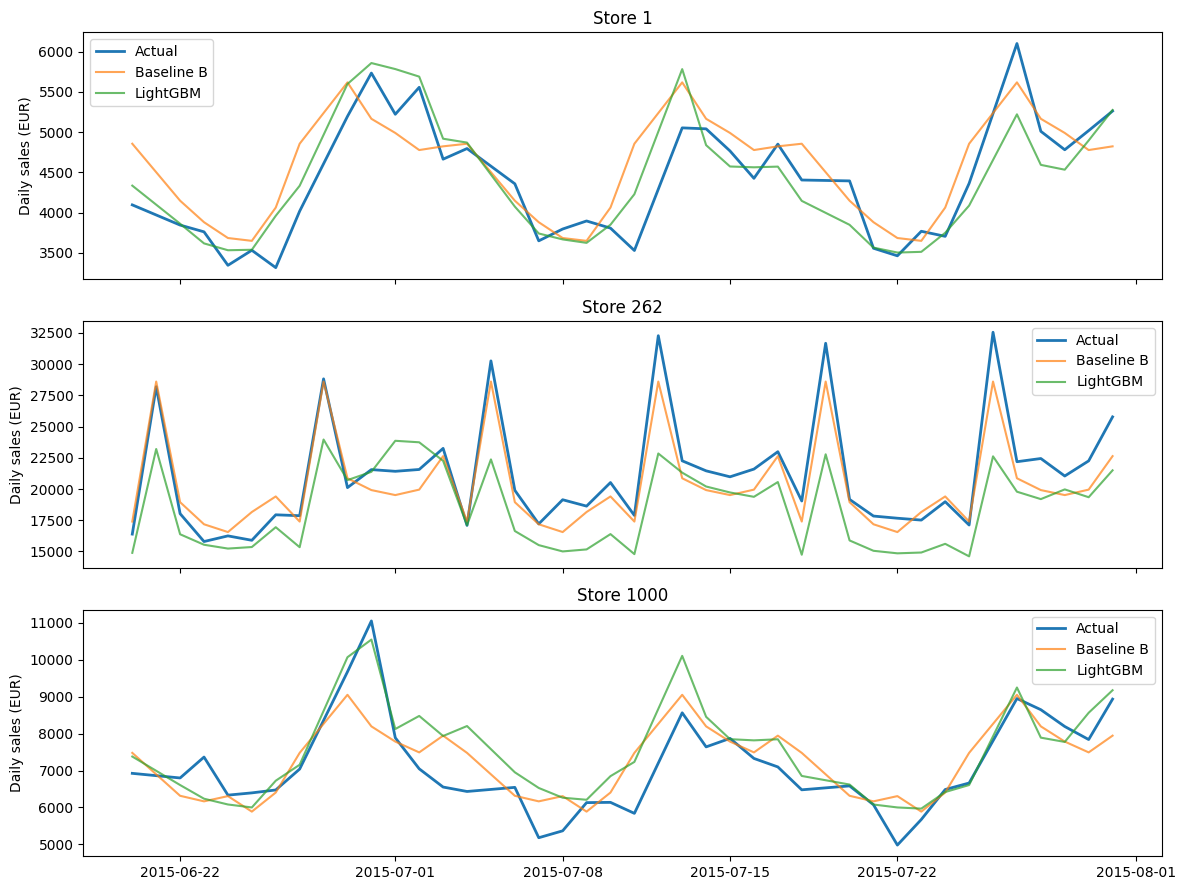

In [10]:
example_stores = [1, 262, 1000]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, s in zip(axes, example_stores):
    r = results[results['Store'] == s].sort_values('Date')
    ax.plot(r['Date'], r['Sales'], label='Actual', linewidth=2)
    ax.plot(r['Date'], r['pred_baseline'], label='Baseline B', alpha=0.7)
    ax.plot(r['Date'], r['pred_lgbm'], label='LightGBM', alpha=0.7)
    ax.set_title(f'Store {s}')
    ax.set_ylabel('Daily sales (EUR)')
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + 'forecast_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

- Baseline B (last 52 weeks, geometric mean) is the best simple baseline.
- LightGBM beats Baseline B in all four test windows, but only by 0.4 to 1.4 RMSPE points
  (mean 14.4% vs. 15.2%). MAE improves by about 5% on average.
- Accuracy differs much more between test windows (12.6% to 16.8% for LightGBM) than
  between models.
- A few stores dominate the error: the worst 1% of rows produce 24% of the squared
  percentage error (e.g. store 292 with an RMSPE above 100%).
- The store ID is the most important feature. Store attributes cannot replace it, but add
  a small improvement on top of it.

## Limitations and next steps

- No lag or rolling features: the models do not know the recent sales level of a store.
- The number of trees chosen by early stopping varies strongly between windows (229 to 859).
  Hyperparameters were not tuned systematically.
- Error analysis and ablation use only the most recent test window and one seed.
- Next step: inspect the worst stores (possible closures or refurbishments).